<a href="https://colab.research.google.com/github/Darl2305/Bank-transaction-fraud/blob/main/bank_transaction_fraud_detection_dataset" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CRISP DM

## Business Understanding:

### El negocio trata de transacciones bancarias
    - Situacion actual: entre 2020 al 2024 hubo un fraude de alrededor de 5.5%
### Criterios de exito:
    - Explorar patrones, visualizar comportamiento fraudulento y crear un modelo de deteccion de fraude.

## Entendimiento de los datos
    - Cantidad de campos y registros
    - Tipo de variables
    - Reporte de exploracion (Estadisticos descriptivos, graficos)
    
## Calidad de los datos
    - Completitud de los datos
    
## Modelado
    - Sleccion de modelos
    - Datos de entrenamiento
    - Construccion del modelo
    - Revision de parametros

## Evaluacion de Resultados
    - Respecto al objetivo del negocio
    - Respecto a los criterios de exito del proyecto

## Despliegue de resultados
    - Plan de despliegue
    - Plan de implementacion y mantenimiento
    - Reporte final

In [ ]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Load dataset
df = pd.read_csv('/kaggle/input/datasets/nafiulislam490/bank-transaction-fraud-detection-dataset/bank_fraud.csv')
df.head()

,transaction_id,customer_id,transaction_date,transaction_time,hour_of_day,is_weekend,is_night_transaction,country,city,merchant_category,...,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud,fraud_type
0,TXN0000000001,CUST00121959,2023-08-17,21:13:00,21,0,0,USA,London,Grocery,...,39.49,157,23,52.7,10.20,0,0,0,0,NaN
1,TXN0000000002,CUST00146868,2024-02-06,05:16:00,5,0,1,UK,New York,Healthcare,...,153.71,153,23,0.9,12.47,0,0,0,0,NaN
2,TXN0000000003,CUST00131933,2024-06-28,12:15:00,12,0,0,Canada,Delhi,Grocery,...,118.20,161,20,9.2,0.08,0,1,0,0,NaN
3,TXN0000000004,CUST00103695,2023-03-16,02:53:00,2,0,1,France,Tokyo,Utilities,...,49.50,160,25,14.8,17.94,1,0,1,1,Synthetic Identity
4,TXN0000000005,CUST00119880,2024-07-12,12:39:00,12,0,0,Canada,Melbourne,Clothing,...,30.74,134,18,38.9,2.16,0,0,0,0,NaN


In [ ]:
df.describe().round(2)

,hour_of_day,is_weekend,is_night_transaction,customer_age,credit_score,account_age_years,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud
count,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00
mean,11.50,0.29,0.38,41.77,679.03,4.99,16594.25,204.72,150.00,20.00,20.01,12.00,0.15,0.38,0.08,0.06
std,6.92,0.45,0.48,13.42,78.83,4.93,28171.46,459.57,12.24,4.47,20.01,12.00,0.36,0.91,0.27,0.23
min,0.00,0.00,0.00,18.00,300.00,0.10,100.00,1.00,96.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,5.00,0.00,0.00,32.00,625.00,1.40,3609.02,33.40,142.00,17.00,5.80,3.45,0.00,0.00,0.00,0.00
50%,11.00,0.00,0.00,42.00,680.00,3.50,8092.12,73.12,150.00,20.00,13.90,8.32,0.00,0.00,0.00,0.00
75%,18.00,1.00,1.00,51.00,734.00,6.90,18225.03,181.45,158.00,23.00,27.70,16.63,0.00,0.00,0.00,0.00
max,23.00,1.00,1.00,85.00,850.00,30.00,500000.00,46129.60,213.00,44.00,292.10,154.20,1.00,5.00,1.00,1.00


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 26 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   transaction_id            1000000 non-null  object 
 1   customer_id               1000000 non-null  object 
 2   transaction_date          1000000 non-null  object 
 3   transaction_time          1000000 non-null  object 
 4   hour_of_day               1000000 non-null  int64  
 5   is_weekend                1000000 non-null  int64  
 6   is_night_transaction      1000000 non-null  int64  
 7   country                   1000000 non-null  object 
 8   city                      1000000 non-null  object 
 9   merchant_category         1000000 non-null  object 
 10  payment_method            1000000 non-null  object 
 11  device_type               1000000 non-null  object 
 12  customer_age              1000000 non-null  int64  
 13  credit_score              10

is_fraud
0    0.94
1    0.06
Name: proportion, dtype: float64

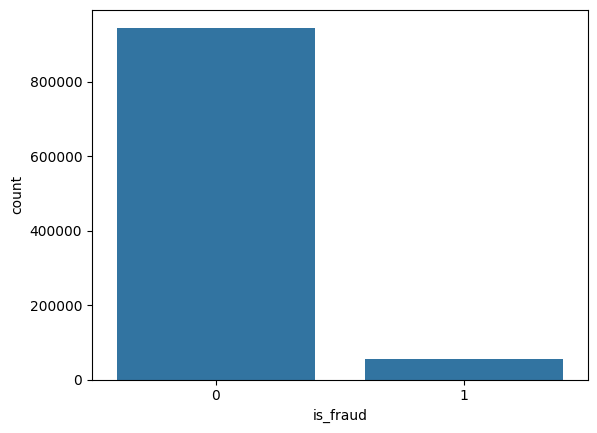

In [ ]:
#Realizamos la distribución de la variables Target
sns.countplot(data = df, x = "is_fraud")
df['is_fraud'].value_counts(1).sort_index(inplace=False).round(2)

* De todos los registro del dataset podemos decir que solo el 0.06% termino en fraude.

In [ ]:
variablesNumericas = df.select_dtypes(include="number").columns.tolist()
print(variablesNumericas)

['hour_of_day', 'is_weekend', 'is_night_transaction', 'customer_age', 'credit_score', 'account_age_years', 'account_balance', 'transaction_amount', 'num_prev_transactions', 'transaction_freq_monthly', 'distance_from_home_km', 'time_since_last_txn_hrs', 'is_international', 'failed_attempts', 'pin_changed_recently', 'is_fraud']


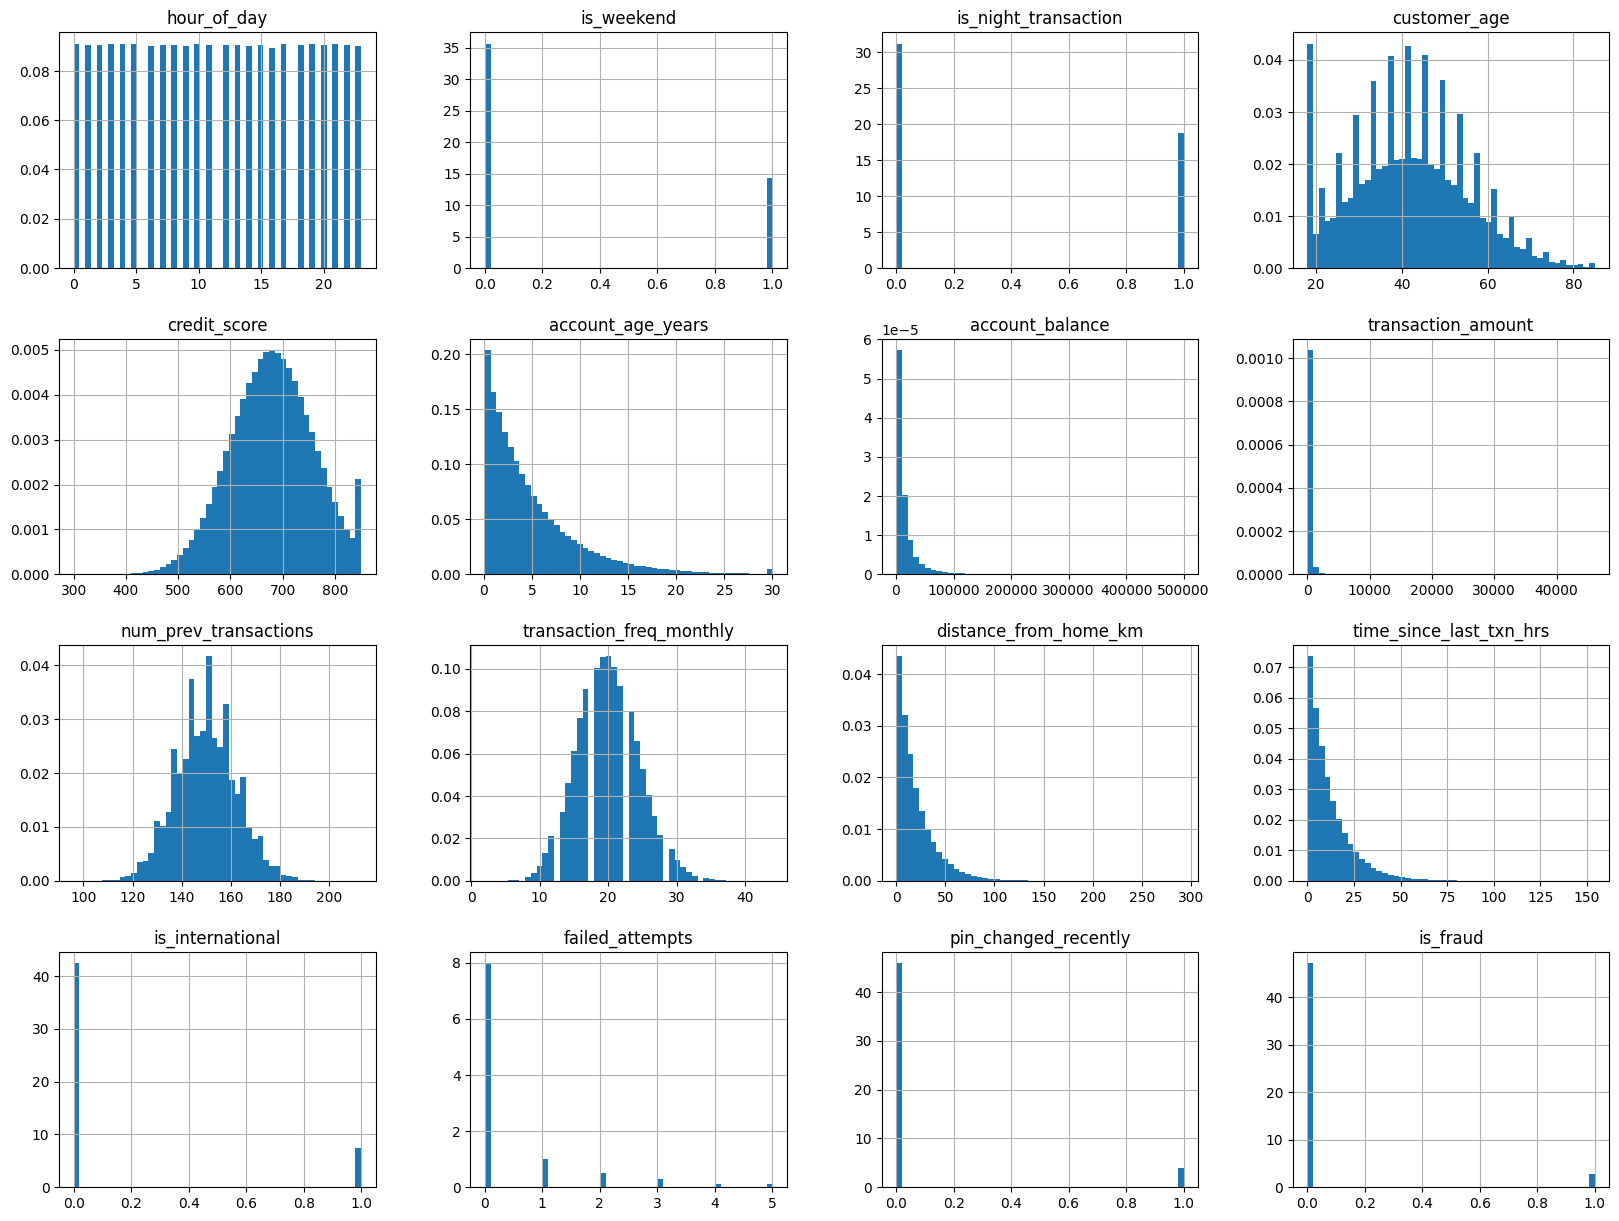

In [ ]:
df[variablesNumericas].hist(
    bins=50,
    figsize=(20, 15),
    density=True
)

plt.show()

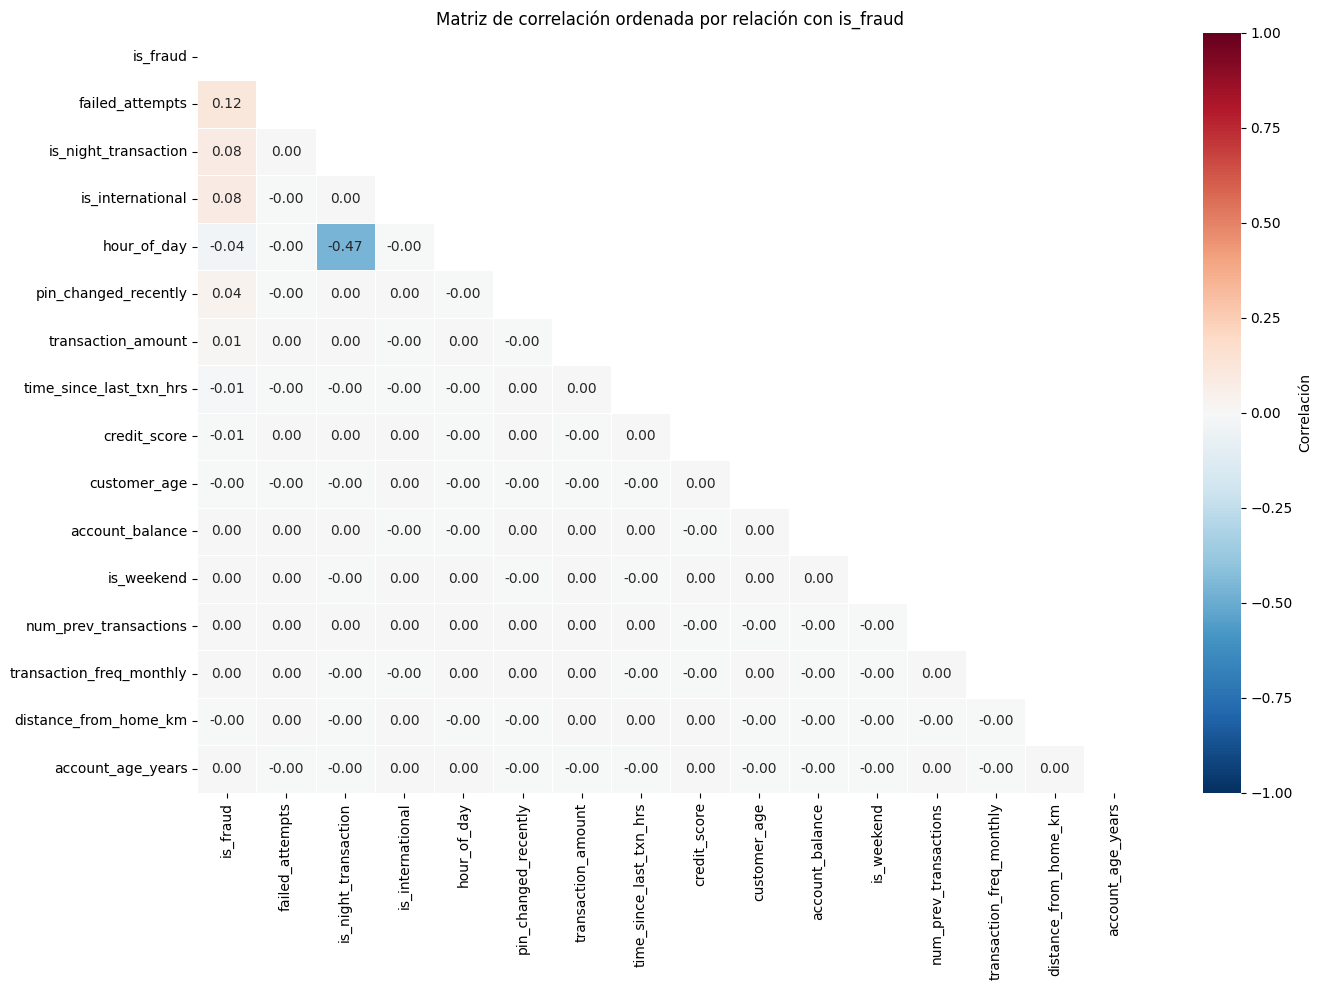

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

target = "is_fraud"

# Matriz de correlación
corr = df[variablesNumericas].corr()

# Ordenar variables según correlación absoluta con el target
orden = corr[target].abs().sort_values(ascending=False).index
corr_ordenada = corr.loc[orden, orden]

# Máscara triangular
mask = np.triu(np.ones_like(corr_ordenada, dtype=bool))

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_ordenada,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",      # azul = negativa, rojo = positiva
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.7,
    linecolor="white",
    cbar_kws={"label": "Correlación"}
)

plt.title("Matriz de correlación ordenada por relación con is_fraud")
plt.tight_layout()
plt.show()

* Las variables numericas con mas correlacion con el target son: failed_attemps, is_night_transaction, is_international

# Variables Categoricas

In [ ]:

variablesCategoricas = df.select_dtypes(include="object").columns.tolist()
print(variablesCategoricas)

['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'country', 'city', 'merchant_category', 'payment_method', 'device_type', 'fraud_type']


In [ ]:
df[['transaction_date', 'is_fraud']].groupby('transaction_date').agg(['count', 'sum', 'mean'])

is_fraud              
                    count sum      mean
transaction_date                       
2020-01-01            572  30  0.052448
2020-01-02            602  23  0.038206
2020-01-03            561  33  0.058824
2020-01-04            568  24  0.042254
2020-01-05            534  28  0.052434
...                   ...  ..       ...
2024-12-26            512  26  0.050781
2024-12-27            562  36  0.064057
2024-12-28            553  34  0.061483
2024-12-29            538  34  0.063197
2024-12-30            525  28  0.053333

[1826 rows x 3 columns]

* Este dataset me indica algunos de las fechas donde hubo fraude y la cantidad en un mismo dia.

In [ ]:
df[['country', 'is_fraud']].groupby('country').agg(['count', 'sum', 'mean'])

is_fraud                 
             count    sum      mean
country                            
Australia    50034   2759  0.055143
Brazil       80351   4552  0.056651
Canada       69742   3879  0.055619
France       69867   3785  0.054174
Germany      79831   4424  0.055417
India       120206   6600  0.054906
Japan        70107   3845  0.054845
Mexico       60275   3295  0.054666
UK           99677   5499  0.055168
USA         299910  16617  0.055407

* Puedo deducir que, los 3 paises donde se detecto mayor fraude bancario fue en India, UK, USA.

In [ ]:
df[['payment_method', 'is_fraud']].groupby('payment_method').agg(['count', 'sum', 'mean'])

is_fraud                 
                  count    sum      mean
payment_method                          
Bank Transfer    150029   8261  0.055063
Cheque            29638   1680  0.056684
Credit Card      349618  19568  0.055970
Crypto            50158   2758  0.054986
Debit Card       300860  16420  0.054577
Mobile Payment   119697   6568  0.054872

* Puedo deducir que, la maayor cantidad con el payment_method fue con Credit Card que a su vez es donde se reaizan las mayores transacciones bancarias.

In [ ]:
df[['device_type', 'is_fraud']].groupby('device_type').agg(['count', 'sum', 'mean'])

is_fraud                 
                count    sum      mean
device_type                           
ATM            100995   5661  0.056052
Desktop        249830  13665  0.054697
Mobile         449114  25024  0.055719
POS Terminal    99960   5435  0.054372
Tablet         100101   5470  0.054645

* Puedo deducir que, con la mayor cantidad de fraude bancario se realiza con el Mobile, que a su vez es donde se realizan las mayores transacciones bancarias.

# Outliers

In [ ]:
print(variablesNumericas)

['hour_of_day', 'is_weekend', 'is_night_transaction', 'customer_age', 'credit_score', 'account_age_years', 'account_balance', 'transaction_amount', 'num_prev_transactions', 'transaction_freq_monthly', 'distance_from_home_km', 'time_since_last_txn_hrs', 'is_international', 'failed_attempts', 'pin_changed_recently', 'is_fraud']


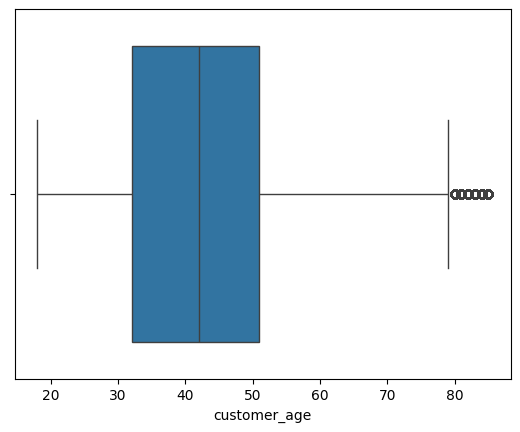

In [ ]:
sns.boxplot(data=df,x='customer_age')
plt.show()

* La edad de los clientes presenta una mediana cercana a los 42 años, con el 50% central de las observaciones aproximadamente entre 32 y 51 años. Se identifican algunos valores atípicos en edades superiores a 80 años, lo que indica una ligera asimetría hacia la derecha.

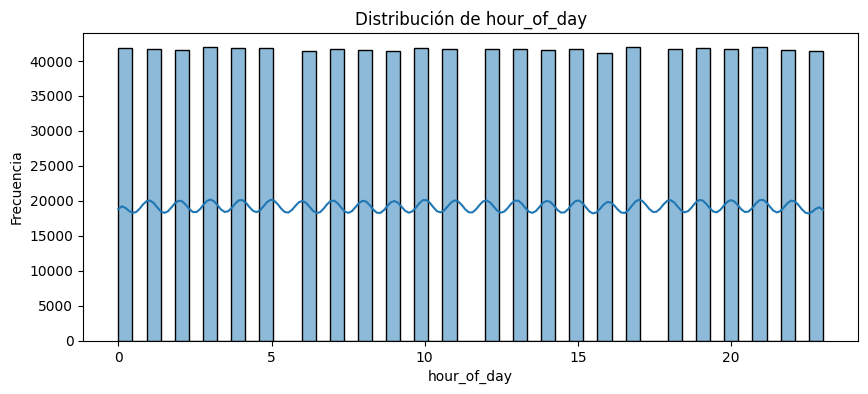

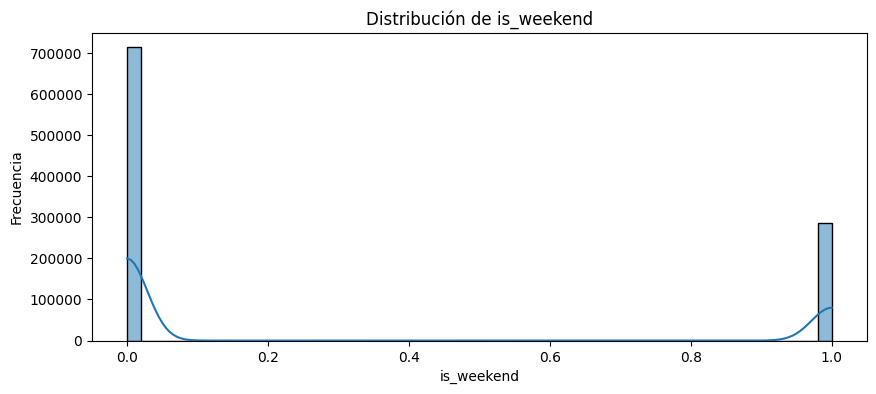

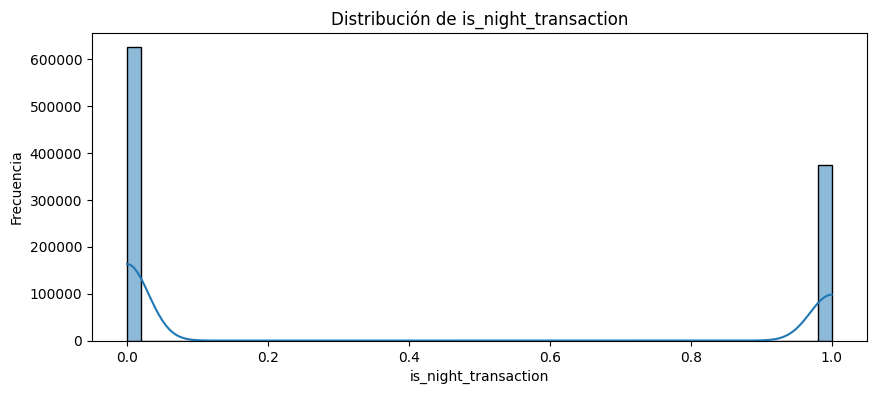

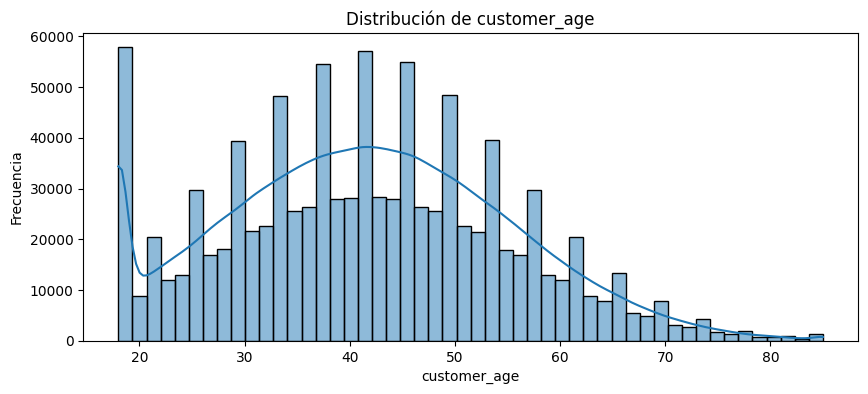

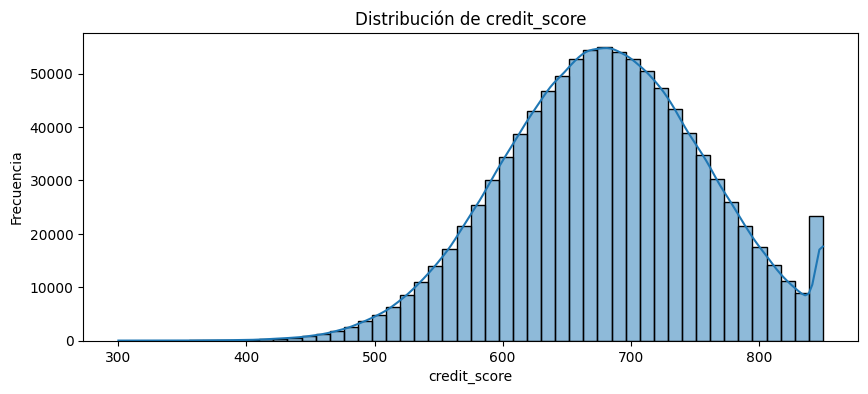

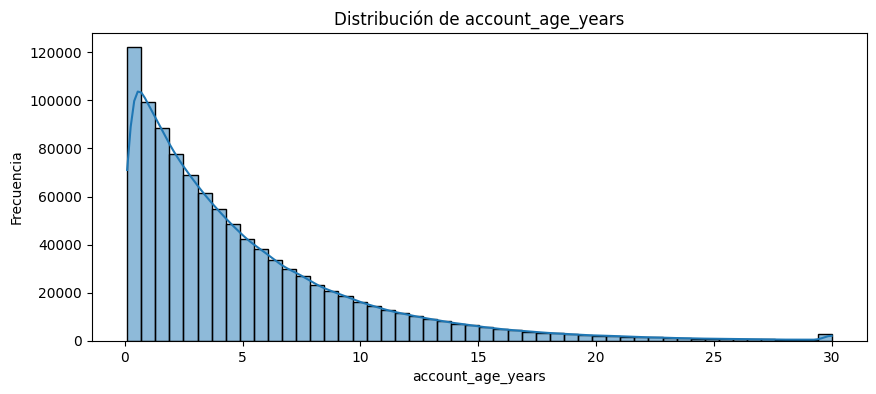

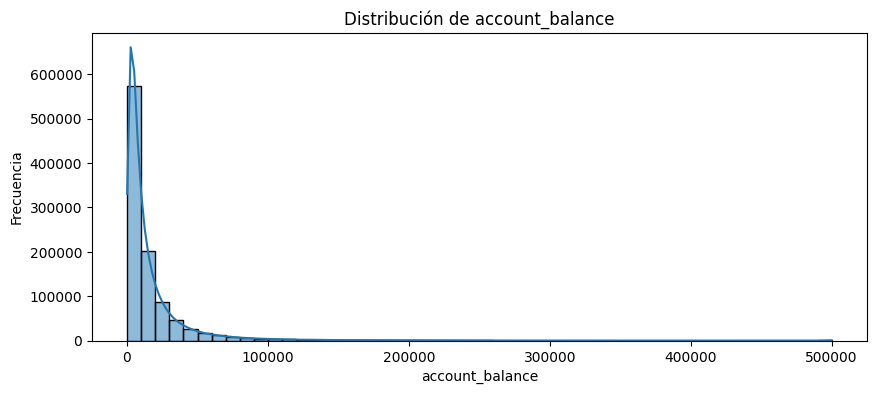

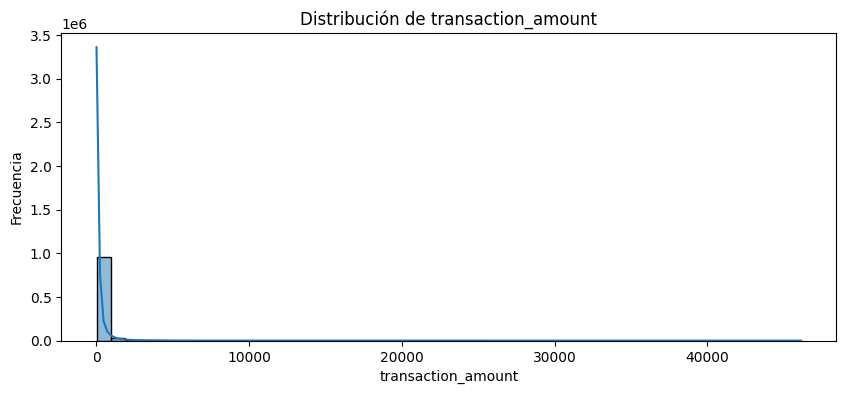

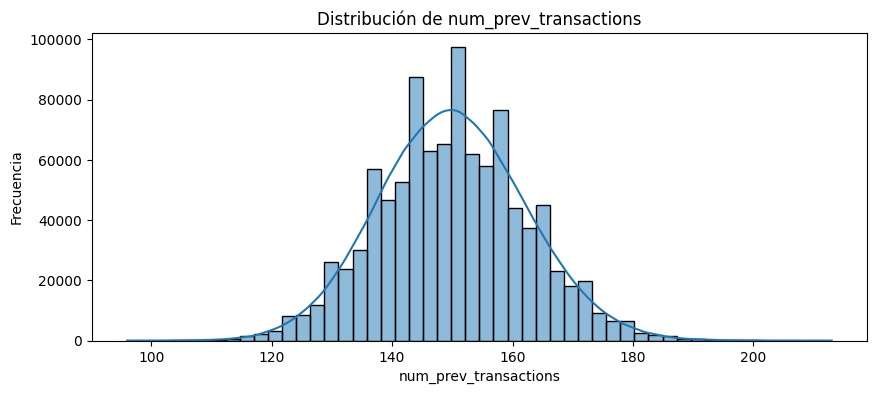

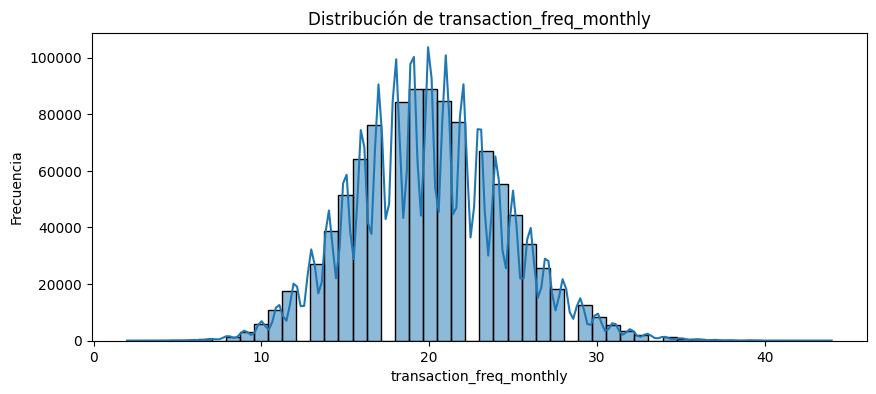

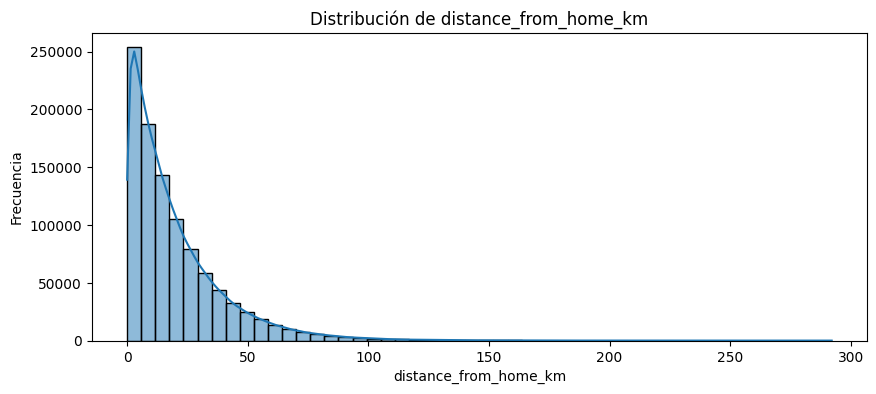

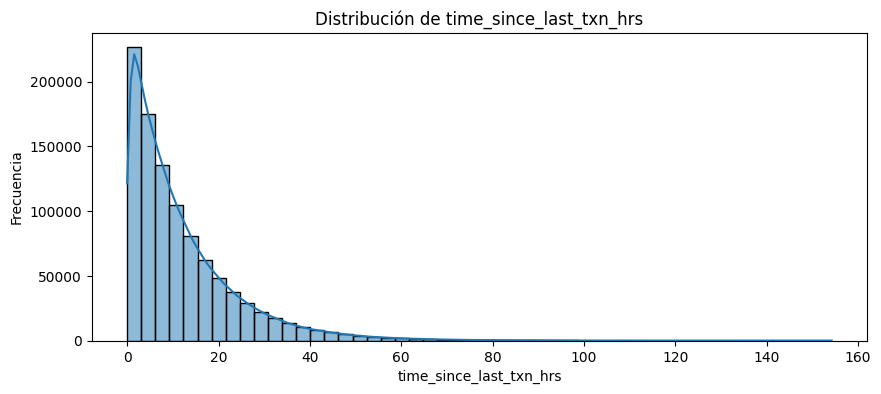

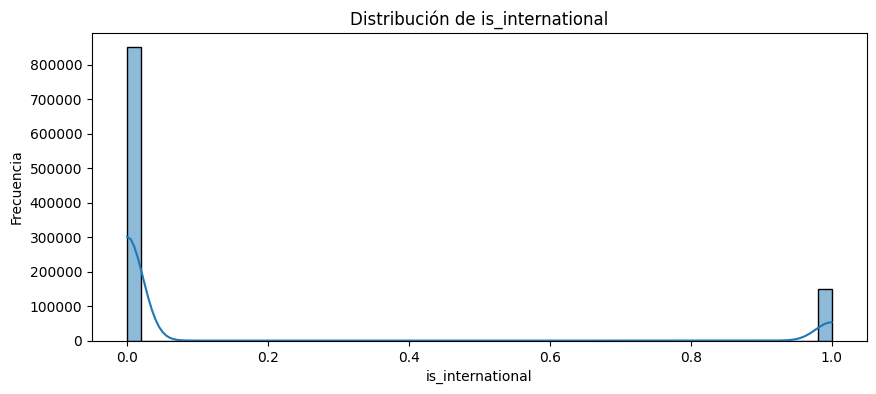

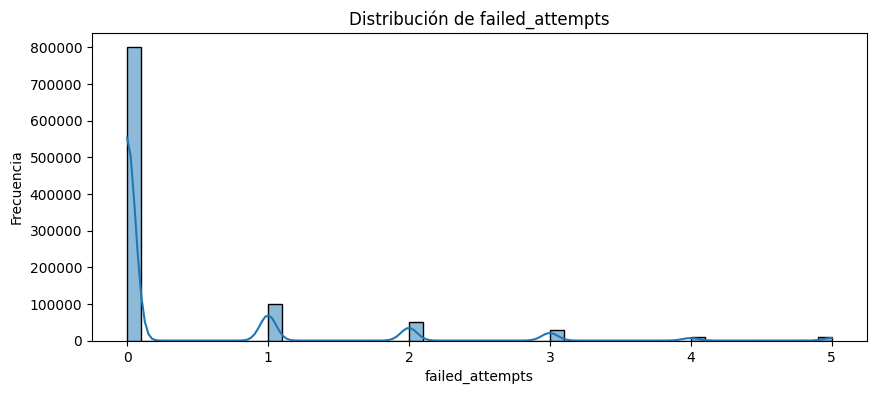

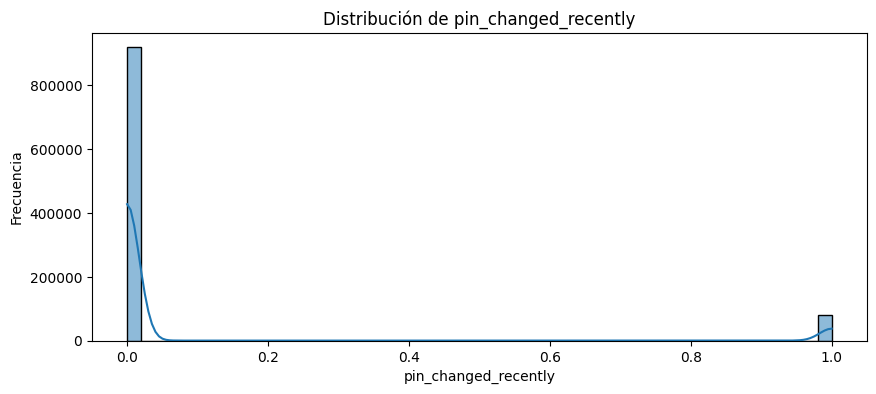

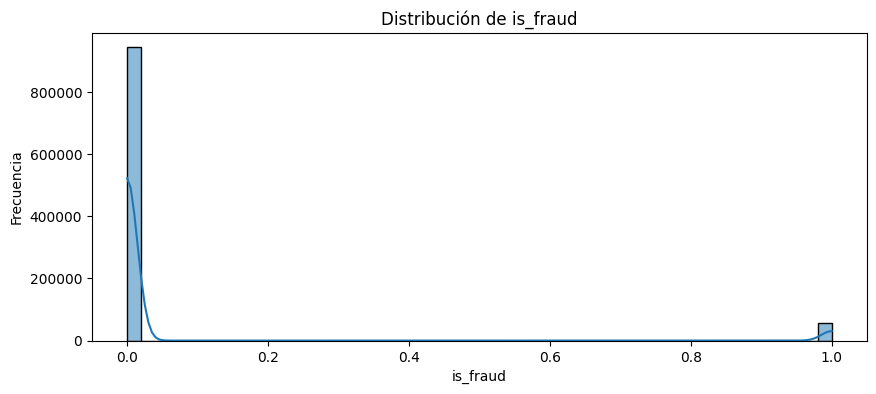

In [ ]:
# Variables numéricas
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:

    plt.figure(figsize=(10, 4))

    sns.histplot(
        data=df,
        x=col,
        bins=50,
        kde=True
    )

    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')

    plt.show()

# Feature Engineering


In [ ]:
df.select_dtypes(include='number').skew().sort_values(ascending=False) # Medimos la asimetria de una distribucion

# Skew entre -0.5 y 0.5  → bastante simétrica

# Entre 0.5 y 1 o -0.5 y -1 → asimetría moderada

# Mayor que 1 → asimetría fuerte hacia la derecha

# Menor que -1 → asimetría fuerte hacia la izquierda

transaction_amount          10.197626
account_balance              6.418896
is_fraud                     3.893128
pin_changed_recently         3.085334
failed_attempts              2.872729
time_since_last_txn_hrs      2.007829
distance_from_home_km        2.005804
is_international             1.960461
account_age_years            1.814420
is_weekend                   0.947017
is_night_transaction         0.516147
transaction_freq_monthly     0.221198
customer_age                 0.212420
num_prev_transactions        0.082307
hour_of_day                  0.000153
credit_score                -0.095274
dtype: float64

In [ ]:
cols_log = [
    'transaction_amount',
    'account_balance',
    'account_age_years',
    'distance_from_home_km',
    'time_since_last_txn_hrs'
]

import numpy as np

for col in cols_log:
    df[col + '_log'] = np.log1p(df[col])

In [ ]:
for col in cols_log:
    print(f'\n{col}')
    print('Skew original:', df[col].skew())
    print('Skew log1p   :', df[col + '_log'].skew())


transaction_amount
Skew original: 10.197625665175984
Skew log1p   : 0.42379792345793693

account_balance
Skew original: 6.418896475406684
Skew log1p   : -0.0002634659965802429

account_age_years
Skew original: 1.814419937764981
Skew log1p   : 0.08848506351465404

distance_from_home_km
Skew original: 2.005803845889596
Skew log1p   : -0.35386023473539774

time_since_last_txn_hrs
Skew original: 2.0078286792564595
Skew log1p   : -0.20089034840505768


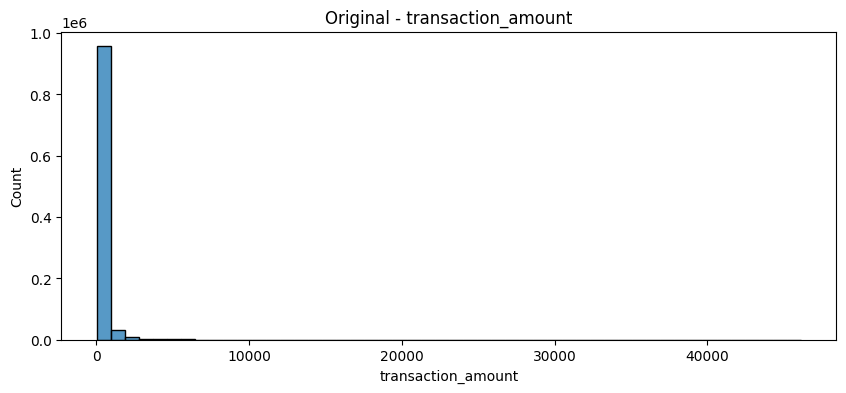

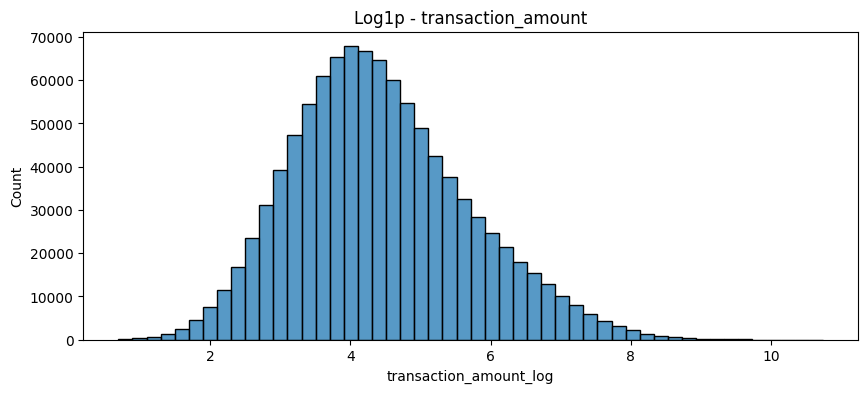

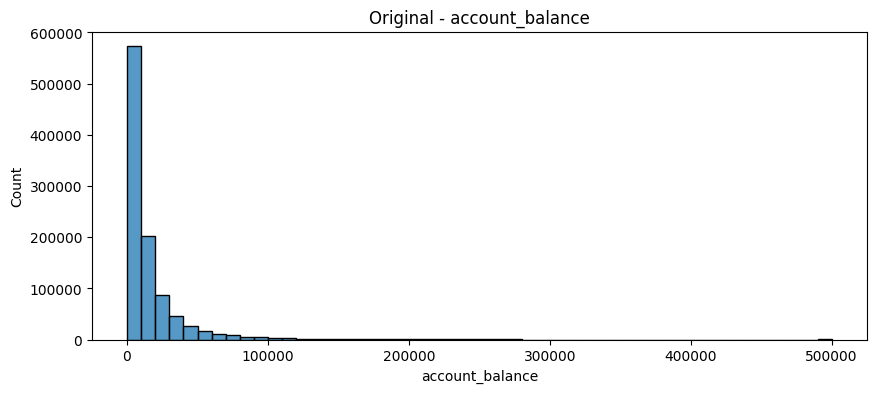

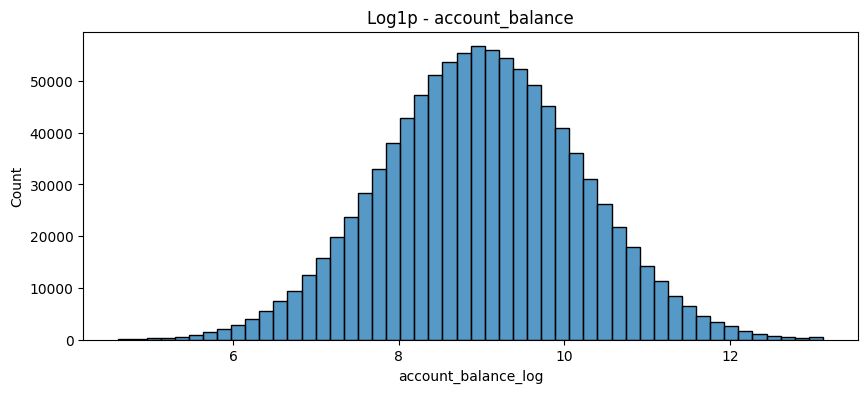

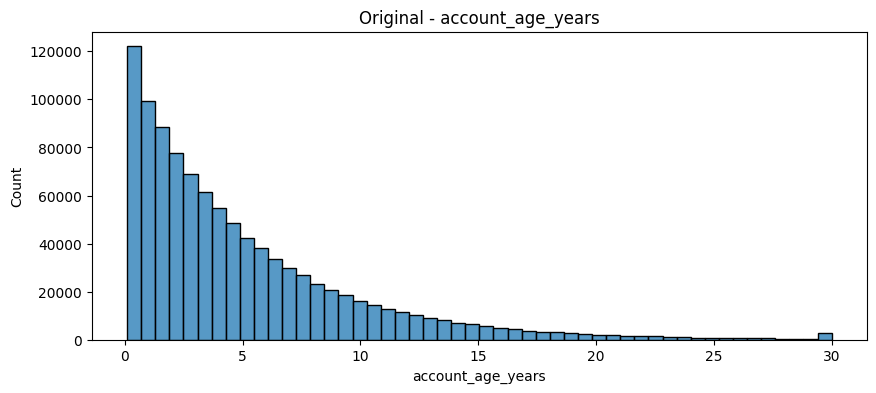

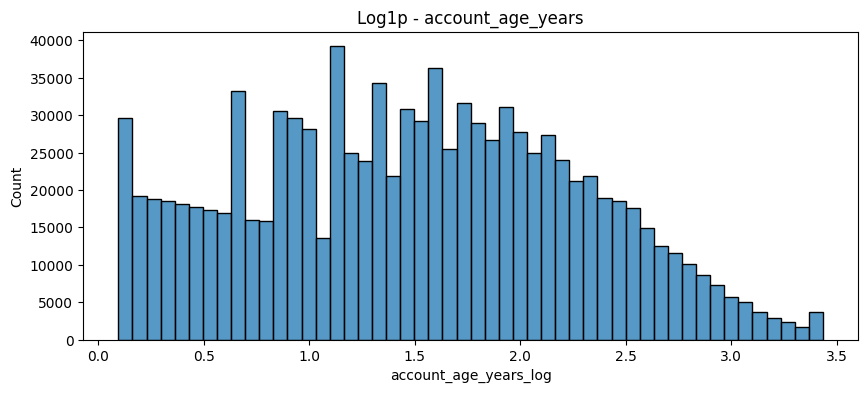

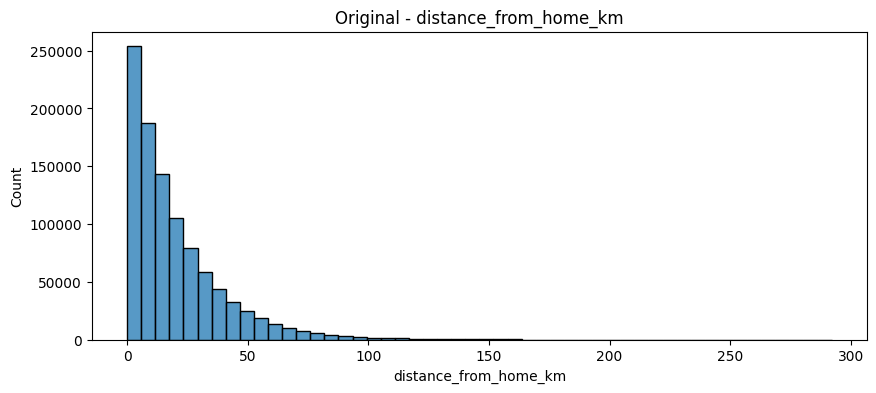

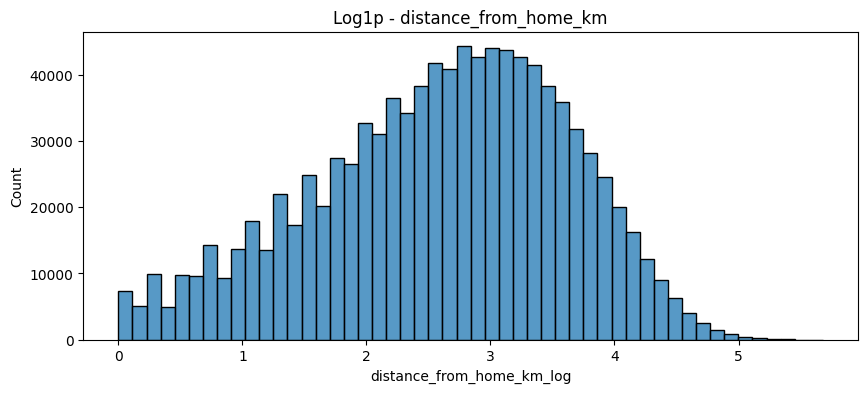

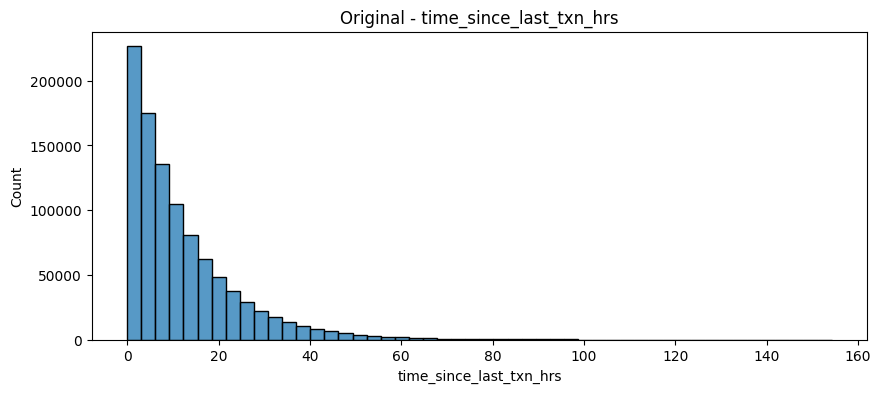

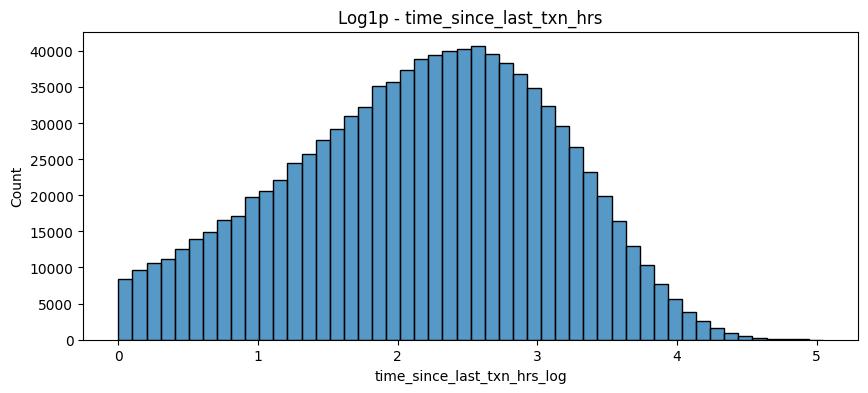

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in cols_log:

    plt.figure(figsize=(10,4))
    sns.histplot(df[col], bins=50)
    plt.title(f'Original - {col}')
    plt.show()

    plt.figure(figsize=(10,4))
    sns.histplot(df[col + '_log'], bins=50)
    plt.title(f'Log1p - {col}')
    plt.show()

# Damizando Variables Categoricas

In [ ]:
# Viendo que usar para damizar

categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_cols:
    print(
        col,
        '→',
        df[col].nunique(),
        'categorías'
    )

transaction_id → 1000000 categorías
customer_id → 198662 categorías
transaction_date → 1826 categorías
transaction_time → 1440 categorías
country → 10 categorías
city → 20 categorías
merchant_category → 15 categorías
payment_method → 6 categorías
device_type → 5 categorías
fraud_type → 6 categorías


In [ ]:
# transaction_id: eliminar / Tiene 1 millón de valores para 1 millón de registros. Es prácticamente un identificador único.

df.groupby(['fraud_type', 'is_fraud']).size()



fraud_type          is_fraud
Account Takeover    1           9232
Card Cloning        1           9200
Friendly Fraud      1           9187
Identity Theft      1           9170
Phishing            1           9252
Synthetic Identity  1           9214
dtype: int64

In [ ]:
cols_onehot = [
    'country',
    'city',
    'merchant_category',
    'payment_method',
    'device_type'
]

df_encoded = pd.get_dummies(
    df,
    columns=cols_onehot,
    drop_first=True
)

In [ ]:
df_model = df_encoded.drop(columns=[
    'transaction_id',
    'customer_id',
    'transaction_date',
    'transaction_time',
    'fraud_type'
])

In [ ]:
df_model.select_dtypes(include=['object', 'category']).columns

Index([], dtype='object')

In [ ]:
df_model.head()

,hour_of_day,is_weekend,is_night_transaction,customer_age,credit_score,account_age_years,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,...,merchant_category_Utilities,payment_method_Cheque,payment_method_Credit Card,payment_method_Crypto,payment_method_Debit Card,payment_method_Mobile Payment,device_type_Desktop,device_type_Mobile,device_type_POS Terminal,device_type_Tablet
0,21,0,0,18,695,7.2,369.36,39.49,157,23,...,False,False,False,False,False,False,False,False,True,False
1,5,0,1,30,600,8.6,2681.99,153.71,153,23,...,False,True,False,False,False,False,True,False,False,False
2,12,0,0,20,711,10.8,44590.64,118.20,161,20,...,False,False,False,True,False,False,False,True,False,False
3,2,0,1,29,711,7.3,1213.37,49.50,160,25,...,True,False,False,False,True,False,False,True,False,False
4,12,0,0,49,751,11.8,34615.01,30.74,134,18,...,False,False,False,False,True,False,True,False,False,False


In [ ]:
print(df_model.columns.tolist())

['hour_of_day', 'is_weekend', 'is_night_transaction', 'customer_age', 'credit_score', 'account_age_years', 'account_balance', 'transaction_amount', 'num_prev_transactions', 'transaction_freq_monthly', 'distance_from_home_km', 'time_since_last_txn_hrs', 'is_international', 'failed_attempts', 'pin_changed_recently', 'is_fraud', 'transaction_amount_log', 'account_balance_log', 'account_age_years_log', 'distance_from_home_km_log', 'time_since_last_txn_hrs_log', 'country_Brazil', 'country_Canada', 'country_France', 'country_Germany', 'country_India', 'country_Japan', 'country_Mexico', 'country_UK', 'country_USA', 'city_Delhi', 'city_Guadalajara', 'city_London', 'city_Los Angeles', 'city_Lyon', 'city_Manchester', 'city_Melbourne', 'city_Mexico City', 'city_Mumbai', 'city_Munich', 'city_New York', 'city_Osaka', 'city_Paris', 'city_Rio', 'city_Sydney', 'city_São Paulo', 'city_Tokyo', 'city_Toronto', 'city_Vancouver', 'merchant_category_Clothing', 'merchant_category_Crypto Exchange', 'merchant_

# Imputacion de Nulos

In [ ]:
df.info()

# Debido a que la unica variable que tiene nulos es el target no se imputara datos ahora, sino cuando estemos en el modelo.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 31 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   transaction_id               1000000 non-null  object 
 1   customer_id                  1000000 non-null  object 
 2   transaction_date             1000000 non-null  object 
 3   transaction_time             1000000 non-null  object 
 4   hour_of_day                  1000000 non-null  int64  
 5   is_weekend                   1000000 non-null  int64  
 6   is_night_transaction         1000000 non-null  int64  
 7   country                      1000000 non-null  object 
 8   city                         1000000 non-null  object 
 9   merchant_category            1000000 non-null  object 
 10  payment_method               1000000 non-null  object 
 11  device_type                  1000000 non-null  object 
 12  customer_age                 1000000 non-nu

# Entrenando el Modelo

In [ ]:
X = df_model.drop(columns='is_fraud')
y = df_model['is_fraud']

In [ ]:
print(X.shape)
print(y.shape)

(1000000, 71)
(1000000,)


In [ ]:
print(y.value_counts())
print(y.value_counts(normalize=True))

is_fraud
0    944745
1     55255
Name: count, dtype: int64
is_fraud
0    0.944745
1    0.055255
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns='is_fraud')
y = df_model['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [ ]:
print("TRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTEST")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

TRAIN
is_fraud
0    755796
1     44204
Name: count, dtype: int64
is_fraud
0    0.944745
1    0.055255
Name: proportion, dtype: float64

TEST
is_fraud
0    188949
1     11051
Name: count, dtype: int64
is_fraud
0    0.944745
1    0.055255
Name: proportion, dtype: float64


In [ ]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(
    random_state=42
)

X_train_under, y_train_under = rus.fit_resample(
    X_train,
    y_train
)

print(y_train_under.value_counts())
print(y_train_under.value_counts(normalize=True))

is_fraud
0    44204
1    44204
Name: count, dtype: int64
is_fraud
0    0.5
1    0.5
Name: proportion, dtype: float64


In [ ]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(
    random_state=42
)

X_train_over, y_train_over = ros.fit_resample(
    X_train,
    y_train
)

print(y_train_over.value_counts())

is_fraud
0    755796
1    755796
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Modelo con undersampling
model_under = LogisticRegression(max_iter=1000)

model_under.fit(
    X_train_under,
    y_train_under
)

pred_under = model_under.predict(X_test)

print("UNDERSAMPLING")
print(classification_report(y_test, pred_under))

UNDERSAMPLING
              precision    recall  f1-score   support

           0       0.96      0.75      0.84    188949
           1       0.10      0.46      0.16     11051

    accuracy                           0.74    200000
   macro avg       0.53      0.61      0.50    200000
weighted avg       0.91      0.74      0.81    200000



In [ ]:
model_over = LogisticRegression(max_iter=1000)

model_over.fit(
    X_train_over,
    y_train_over
)

pred_over = model_over.predict(X_test)

print("OVERSAMPLING")
print(classification_report(y_test, pred_over))

OVERSAMPLING
              precision    recall  f1-score   support

           0       0.96      0.75      0.85    188949
           1       0.10      0.46      0.16     11051

    accuracy                           0.74    200000
   macro avg       0.53      0.61      0.50    200000
weighted avg       0.91      0.74      0.81    200000



In [ ]:
bool_cols = X_train.select_dtypes(include='bool').columns

print(bool_cols)
print("Cantidad de columnas booleanas:", len(bool_cols))

Index(['country_Brazil', 'country_Canada', 'country_France', 'country_Germany',
       'country_India', 'country_Japan', 'country_Mexico', 'country_UK',
       'country_USA', 'city_Delhi', 'city_Guadalajara', 'city_London',
       'city_Los Angeles', 'city_Lyon', 'city_Manchester', 'city_Melbourne',
       'city_Mexico City', 'city_Mumbai', 'city_Munich', 'city_New York',
       'city_Osaka', 'city_Paris', 'city_Rio', 'city_Sydney', 'city_São Paulo',
       'city_Tokyo', 'city_Toronto', 'city_Vancouver',
       'merchant_category_Clothing', 'merchant_category_Crypto Exchange',
       'merchant_category_Education', 'merchant_category_Electronics',
       'merchant_category_Entertainment', 'merchant_category_Fuel',
       'merchant_category_Gaming', 'merchant_category_Grocery',
       'merchant_category_Healthcare', 'merchant_category_Jewelry',
       'merchant_category_Online Shopping', 'merchant_category_Restaurant',
       'merchant_category_Travel', 'merchant_category_Utilities',
   

In [ ]:
categorical_indices = [
    X_train.columns.get_loc(col)
    for col in bool_cols
]

In [ ]:
from imblearn.over_sampling import SMOTENC

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_smotenc, y_train_smotenc = smotenc.fit_resample(
    X_train,
    y_train
)

In [ ]:
print(y_train_smotenc.value_counts())
print(y_train_smotenc.value_counts(normalize=True))

is_fraud
0    755796
1    755796
Name: count, dtype: int64
is_fraud
0    0.5
1    0.5
Name: proportion, dtype: float64
